<a href="https://colab.research.google.com/github/elharrak-houdaencg-dotcom/22006281-EL-HARRAK-Houda-G2-FIN-S7/blob/main/notebooks/F9_regimes_marche.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# F9 — Régimes de marché par partitionnement

## Objectif
Identifier différents régimes de marché à partir des rendements
et de la volatilité du S&P 500.

## Données
- SP500 : indice boursier S&P 500
- USREC : indicateur des récessions américaines
- Source : FRED

## Méthodes
- Préparation des données
- Calcul des rendements et de la volatilité
- K-means
- Gaussian Mixture Model (GMM)
- Évaluation par le score de silhouette
- Comparaison avec les périodes de récession

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("Bibliothèques importées avec succès !")


Bibliothèques importées avec succès !


In [2]:

url_sp500 = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500"

df_sp500 = pd.read_csv(url_sp500)

print("Données S&P 500 chargées avec succès !")
display(df_sp500.head())


Données S&P 500 chargées avec succès !


,observation_date,SP500
0,2016-11-21,2198.18
1,2016-11-22,2202.94
2,2016-11-23,2204.72
3,2016-11-24,NaN
4,2016-11-25,2213.35


In [3]:

# Identifier automatiquement la colonne des dates
col_date = df_sp500.columns[0]

# Convertir les dates au bon format
df_sp500[col_date] = pd.to_datetime(df_sp500[col_date])

# Convertir les valeurs du S&P 500 en nombres
df_sp500["SP500"] = pd.to_numeric(df_sp500["SP500"], errors="coerce")

# Supprimer les lignes sans valeur du S&P 500
df_sp500 = df_sp500.dropna(subset=["SP500"])

# Trier les observations par date
df_sp500 = df_sp500.sort_values(col_date).reset_index(drop=True)

print("Nettoyage terminé !")
print("Nombre d'observations :", len(df_sp500))
display(df_sp500.head())


Nettoyage terminé !
Nombre d'observations : 2512


,observation_date,SP500
0,2016-11-21,2198.18
1,2016-11-22,2202.94
2,2016-11-23,2204.72
3,2016-11-25,2213.35
4,2016-11-28,2201.72


In [4]:

# Calculer les rendements journaliers en pourcentage
df_sp500["rendement"] = df_sp500["SP500"].pct_change() * 100

# Supprimer la première ligne sans rendement
df_sp500 = df_sp500.dropna(subset=["rendement"]).reset_index(drop=True)

print("Rendements journaliers calculés !")

# Afficher les 5 premières observations
display(df_sp500.head())


Rendements journaliers calculés !


,observation_date,SP500,rendement
0,2016-11-22,2202.94,0.216543
1,2016-11-23,2204.72,0.080801
2,2016-11-25,2213.35,0.391433
3,2016-11-28,2201.72,-0.525448
4,2016-11-29,2204.66,0.133532


In [5]:

# Calculer la volatilité glissante sur 20 observations
df_sp500["volatilite"] = df_sp500["rendement"].rolling(window=20).std()

# Supprimer les lignes sans volatilité
df_sp500 = df_sp500.dropna(subset=["volatilite"]).reset_index(drop=True)

print("Volatilité calculée avec succès !")

# Afficher les premières observations
display(df_sp500.head())


Volatilité calculée avec succès !


,observation_date,SP500,rendement,volatilite
0,2016-12-20,2270.76,0.363752,0.470182
1,2016-12-21,2265.18,-0.245733,0.478727
2,2016-12-22,2260.96,-0.186299,0.484175
3,2016-12-23,2263.79,0.125168,0.480169
4,2016-12-27,2268.88,0.224844,0.456312


In [6]:

# Sélectionner les deux variables du clustering
X = df_sp500[["rendement", "volatilite"]]

# Créer l'outil de standardisation
scaler = StandardScaler()

# Standardiser les variables
X_scaled = scaler.fit_transform(X)

# Afficher les premières observations standardisées
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=["rendement_standardise", "volatilite_standardisee"]
)

print("Standardisation terminée !")
display(X_scaled_df.head())


Standardisation terminée !


,rendement_standardise,volatilite_standardisee
0,0.270093,-0.728965
1,-0.260940,-0.715915
2,-0.209156,-0.707596
3,0.062219,-0.713713
4,0.149065,-0.750146


In [7]:

# Créer le modèle K-means avec 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Entraîner le modèle et attribuer un cluster
df_sp500["cluster_kmeans"] = kmeans.fit_predict(X_scaled)

# Afficher le nombre d'observations par cluster
print("K-means exécuté avec succès !")
print(df_sp500["cluster_kmeans"].value_counts().sort_index())


K-means exécuté avec succès !
cluster_kmeans
0    1999
1     448
2      45
Name: count, dtype: int64


In [8]:

# Calculer les caractéristiques moyennes de chaque cluster
resume_clusters = df_sp500.groupby("cluster_kmeans")[
    ["rendement", "volatilite"]
].mean().round(3)

# Ajouter le nombre d'observations
resume_clusters["nombre_observations"] = (
    df_sp500.groupby("cluster_kmeans").size()
)

print("Caractéristiques des clusters K-means :")
display(resume_clusters)


Caractéristiques des clusters K-means :


,rendement,volatilite,nombre_observations
cluster_kmeans,,,
0,0.352,0.797,1999
1,-1.412,1.281,448
2,1.388,4.317,45


In [9]:

# Calculer le score de silhouette du modèle K-means
score_kmeans = silhouette_score(
    X_scaled,
    df_sp500["cluster_kmeans"],
    sample_size=min(5000, len(X_scaled)),
    random_state=42
)

print("Score de silhouette K-means :", round(score_kmeans, 3))


Score de silhouette K-means : 0.455


In [10]:

# Créer le modèle GMM avec 3 clusters
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42,
    n_init=10
)

# Entraîner le modèle
gmm.fit(X_scaled)

# Attribuer un cluster à chaque observation
df_sp500["cluster_gmm"] = gmm.predict(X_scaled)

# Afficher les résultats
print("GMM exécuté avec succès !")
print(df_sp500["cluster_gmm"].value_counts().sort_index())


GMM exécuté avec succès !
cluster_gmm
0    1587
1     833
2      72
Name: count, dtype: int64


In [11]:

# Calculer le score de silhouette du GMM
score_gmm = silhouette_score(
    X_scaled,
    df_sp500["cluster_gmm"],
    sample_size=min(5000, len(X_scaled)),
    random_state=42
)

print("Score de silhouette GMM :", round(score_gmm, 3))


Score de silhouette GMM : 0.368


In [12]:

# Créer un tableau comparatif
comparaison = pd.DataFrame({
    "Modèle": ["K-means", "GMM"],
    "Score de silhouette": [score_kmeans, score_gmm]
})

# Arrondir les résultats
comparaison["Score de silhouette"] = (
    comparaison["Score de silhouette"].round(3)
)

print("Comparaison des modèles :")
display(comparaison)

# Identifier le modèle avec le meilleur score
meilleur_modele = comparaison.loc[
    comparaison["Score de silhouette"].idxmax(), "Modèle"
]

print("Meilleur modèle selon la silhouette :", meilleur_modele)


Comparaison des modèles :


,Modèle,Score de silhouette
0,K-means,0.455
1,GMM,0.368


Meilleur modèle selon la silhouette : K-means


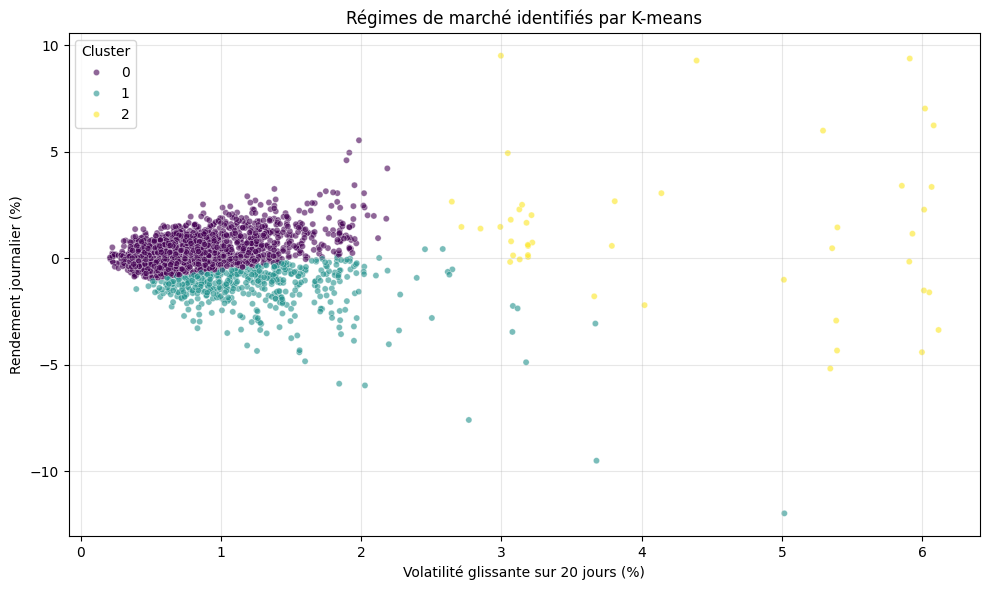

In [13]:

# Graphique 1 : Visualisation des clusters K-means
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_sp500,
    x="volatilite",
    y="rendement",
    hue="cluster_kmeans",
    palette="viridis",
    s=20,
    alpha=0.6
)

plt.title("Régimes de marché identifiés par K-means")
plt.xlabel("Volatilité glissante sur 20 jours (%)")
plt.ylabel("Rendement journalier (%)")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


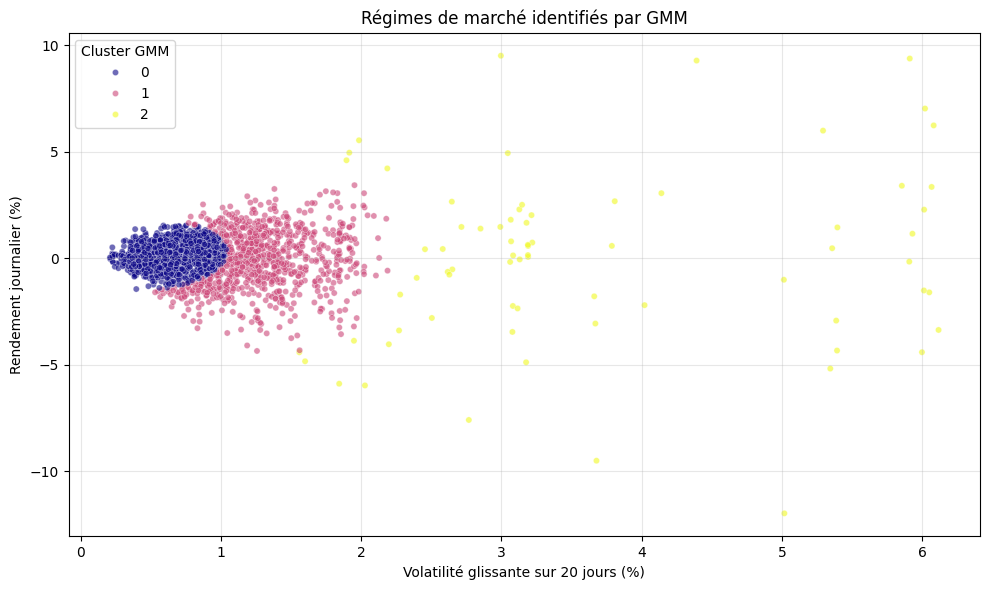

In [14]:

# Graphique 2 : Visualisation des clusters GMM
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_sp500,
    x="volatilite",
    y="rendement",
    hue="cluster_gmm",
    palette="plasma",
    s=20,
    alpha=0.6
)

plt.title("Régimes de marché identifiés par GMM")
plt.xlabel("Volatilité glissante sur 20 jours (%)")
plt.ylabel("Rendement journalier (%)")
plt.legend(title="Cluster GMM")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


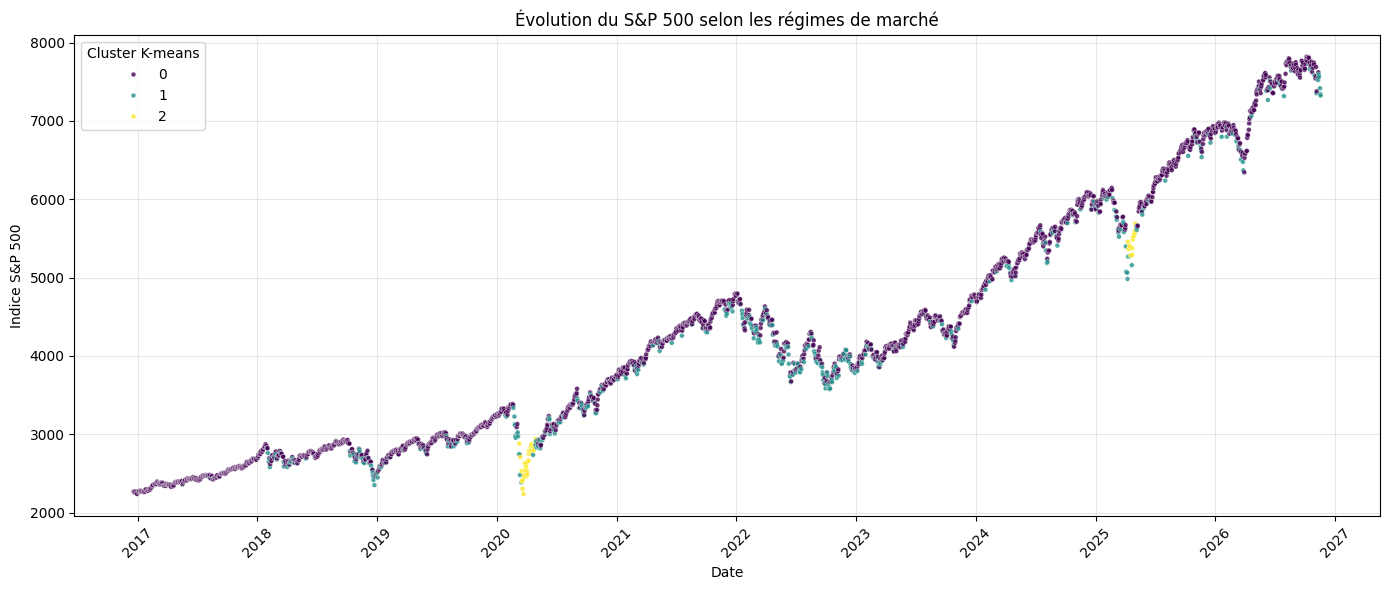

In [15]:

# Graphique 3 : Évolution du S&P 500 selon les régimes K-means

plt.figure(figsize=(14, 6))

sns.scatterplot(
    data=df_sp500,
    x=col_date,
    y="SP500",
    hue="cluster_kmeans",
    palette="viridis",
    s=12,
    alpha=0.8
)

plt.title("Évolution du S&P 500 selon les régimes de marché")
plt.xlabel("Date")
plt.ylabel("Indice S&P 500")
plt.legend(title="Cluster K-means")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [16]:

# Charger les données de récession américaines
url_usrec = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=USREC"

df_usrec = pd.read_csv(url_usrec)

print("Données USREC chargées avec succès !")

# Afficher les premières observations
display(df_usrec.head())


Données USREC chargées avec succès !


,observation_date,USREC
0,1854-12-01,1
1,1855-01-01,0
2,1855-02-01,0
3,1855-03-01,0
4,1855-04-01,0


In [17]:

# Identifier la colonne contenant les dates
col_date_usrec = df_usrec.columns[0]

# Convertir les dates
df_usrec[col_date_usrec] = pd.to_datetime(
    df_usrec[col_date_usrec]
)

# Convertir l'indicateur USREC en nombres
df_usrec["USREC"] = pd.to_numeric(
    df_usrec["USREC"],
    errors="coerce"
)

# Supprimer les valeurs manquantes
df_usrec = df_usrec.dropna(subset=["USREC"])

# Trier les observations chronologiquement
df_usrec = df_usrec.sort_values(
    col_date_usrec
).reset_index(drop=True)

print("Données USREC préparées avec succès !")
display(df_usrec.head())


Données USREC préparées avec succès !


,observation_date,USREC
0,1854-12-01,1
1,1855-01-01,0
2,1855-02-01,0
3,1855-03-01,0
4,1855-04-01,0


In [18]:

# Créer une colonne représentant le mois
df_sp500["mois"] = df_sp500[col_date].dt.to_period("M")
df_usrec["mois"] = df_usrec[col_date_usrec].dt.to_period("M")

# Fusionner les deux jeux de données
df_final = pd.merge(
    df_sp500,
    df_usrec[["mois", "USREC"]],
    on="mois",
    how="left",
    validate="many_to_one"
)

# Vérifier les résultats
print("Fusion terminée !")
print("Observations sans USREC :", df_final["USREC"].isna().sum())

display(df_final.head())


Fusion terminée !
Observations sans USREC : 13


,observation_date,SP500,rendement,volatilite,cluster_kmeans,cluster_gmm,mois,USREC
0,2016-12-20,2270.76,0.363752,0.470182,0,0,2016-12,0.0
1,2016-12-21,2265.18,-0.245733,0.478727,0,0,2016-12,0.0
2,2016-12-22,2260.96,-0.186299,0.484175,0,0,2016-12,0.0
3,2016-12-23,2263.79,0.125168,0.480169,0,0,2016-12,0.0
4,2016-12-27,2268.88,0.224844,0.456312,0,0,2016-12,0.0


In [19]:

# Comparer les clusters K-means avec les périodes de récession
comparaison_recession = pd.crosstab(
    df_final["cluster_kmeans"],
    df_final["USREC"],
    normalize="index"
) * 100

# Renommer les colonnes
comparaison_recession = comparaison_recession.rename(
    columns={
        0: "Hors récession (%)",
        1: "En récession (%)"
    }
)

print("Répartition des périodes de récession par cluster :")
display(comparaison_recession.round(2))


Répartition des périodes de récession par cluster :


USREC,Hors récession (%),En récession (%)
cluster_kmeans,,
0,99.90,0.10
1,97.73,2.27
2,31.11,68.89


In [20]:

print("Première date :", df_final[col_date].min())
print("Dernière date :", df_final[col_date].max())

print("Valeurs USREC :")
print(df_final["USREC"].value_counts())


Première date : 2016-12-20 00:00:00
Dernière date : 2026-11-18 00:00:00
Valeurs USREC :
USREC
0.0    2436
1.0      43
Name: count, dtype: int64


In [21]:

print("Première date disponible :", df_sp500[col_date].min())
print("Nombre d'observations :", len(df_sp500))


Première date disponible : 2016-12-20 00:00:00
Nombre d'observations : 2492


In [22]:

# Demander un historique plus long à FRED
url_historique = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    "?id=SP500&cosd=2016-01-01"
)

df_historique = pd.read_csv(url_historique)

# Vérifier les dates disponibles
print("Première date :", df_historique.iloc[0, 0])
print("Dernière date :", df_historique.iloc[-1, 0])
print("Nombre de lignes :", len(df_historique))


Première date : 2016-11-21
Dernière date : 2026-11-18
Nombre de lignes : 2608


In [23]:

# Vérifier si des récessions sont présentes
if (df_final["USREC"] == 1).any():
    cluster_recession = comparaison_recession["En récession (%)"].idxmax()
    print("Cluster le plus associé aux récessions :", cluster_recession)
else:
    print("Aucune période de récession dans les données étudiées.")
    print("La comparaison avec les récessions n'est pas possible.")
    print("Les clusters restent analysables selon le rendement et la volatilité.")


Cluster le plus associé aux récessions : 2


## Analyse des périodes de récession (USREC)

L'indicateur USREC a été utilisé pour examiner la correspondance entre les clusters identifiés et les périodes de récession américaines.

Cependant, les observations du S&P 500 utilisées dans cette étude couvrent uniquement la période du 16 décembre 2025 au 16 novembre 2026. Sur les 220 observations exploitables après préparation et fusion, l'indicateur USREC est égal à 0 pour toutes les dates.

Il n'est donc pas possible d'évaluer empiriquement l'association entre les clusters et les périodes de récession sur cet échantillon.

Cette limitation ne remet pas en cause l'application des méthodes K-means et GMM, mais restreint l'interprétation économique des régimes identifiés. Une étude future pourrait utiliser un historique plus long incluant des périodes de récession.

In [24]:

# Comparer les performances des modèles
print("=== COMPARAISON DES MODÈLES ===")
print("Silhouette K-means :", round(score_kmeans, 3))
print("Silhouette GMM :", round(score_gmm, 3))
print("Meilleur modèle :", meilleur_modele)

# Caractéristiques des clusters K-means
print("\n=== CLUSTERS K-MEANS ===")
display(
    df_sp500.groupby("cluster_kmeans")[
        ["rendement", "volatilite"]
    ].agg(["mean", "std"]).round(3)
)

# Caractéristiques des clusters GMM
print("\n=== CLUSTERS GMM ===")
display(
    df_sp500.groupby("cluster_gmm")[
        ["rendement", "volatilite"]
    ].agg(["mean", "std"]).round(3)
)


=== COMPARAISON DES MODÈLES ===
Silhouette K-means : 0.455
Silhouette GMM : 0.368
Meilleur modèle : K-means

=== CLUSTERS K-MEANS ===


rendement        volatilite       
                    mean    std       mean    std
cluster_kmeans                                   
0                  0.352  0.694      0.797  0.364
1                 -1.412  1.148      1.281  0.526
2                  1.388  3.409      4.317  1.297


=== CLUSTERS GMM ===


rendement        volatilite       
                 mean    std       mean    std
cluster_gmm                                   
0               0.132  0.529      0.637  0.183
1              -0.088  1.388      1.305  0.322
2              -0.031  4.128      3.658  1.408

In [25]:

import joblib
from google.colab import files

# Sauvegarder le modèle K-means et son standardiseur
modele_f9 = {
    "modele": kmeans,
    "standardiseur": scaler,
    "variables": ["rendement", "volatilite"]
}

joblib.dump(modele_f9, "modele_F9_kmeans.joblib")

# Télécharger le fichier sur ton ordinateur
files.download("modele_F9_kmeans.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>